# 01 — Regressão linear

**CMP263 (PPGC/UFRGS, 2026/2)** · Grupo: Artur Mariano, Emerson Herrera e Yaser Husein

**Pergunta:** as características estruturais de uma escola (infraestrutura, rede, localização, tamanho, docentes) predizem o desempenho médio dos seus alunos no ENEM 2025?

Este notebook ajusta o modelo mais simples da comparação: **regressão linear por mínimos quadrados** (`sklearn.linear_model.LinearRegression`), sem regularização e sem ajuste de hiperparâmetros. Os outros algoritmos vão usar **os mesmos dados, o mesmo pré-processamento e a mesma validação cruzada**, para que os números sejam comparáveis.

| Item | Escolha |
|---|---|
| Unidade | escola com ≥ 10 candidatos presentes nas 4 provas (23.374 escolas) |
| Alvo | `nota_media`: média, por escola, da média das 5 notas |
| Atributos | 45 atributos do Censo Escolar 2024 (lista em `src/enem_school/config.py`) |
| Validação | `GroupKFold` com 5 dobras, agrupando por município (`CO_MUNICIPIO`) |
| Métricas | RMSE, MAE (em pontos do ENEM) e R² |

### Reprodutibilidade

- Os dados vêm de `scripts/build_dataset.py`, que registra a URL e o SHA-256 de cada arquivo do INEP. A seção 2 confere esses hashes.
- As versões das bibliotecas estão fixadas em `uv.lock` / `requirements.txt`. A última seção imprime as versões usadas na execução.
- A regressão linear e o `GroupKFold` (sem embaralhamento) são determinísticos. A semente (`config.SEED`) é fixada mesmo assim, para os próximos notebooks.
- Para rodar de novo: **Kernel → Restart & Run All** (local) ou **Ambiente de execução → Executar tudo** (Colab). O notebook deve rodar do início ao fim sem intervenção manual.

## 1. Ambiente

A célula abaixo funciona **localmente** e **no Google Colab**:

- **Local:** rode a partir da raiz do repositório, depois de `uv sync --group notebooks`, e abra com `uv run jupyter lab`.
- **Colab:** a célula clona o repositório e instala as versões fixadas em `requirements.txt`. Se o Colab avisar que precisa reiniciar a sessão (por trocar a versão do pandas/numpy), reinicie e rode tudo de novo.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/emersonheto/enem-school-performance.git"
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    repo = Path("/content/enem-school-performance")
    if not repo.exists():
        subprocess.run(["git", "clone", REPO_URL, str(repo)], check=True)
    os.chdir(repo)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# Raiz do repositório: funciona com o notebook aberto em notebooks/ ou na raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
print("Raiz do repositório:", ROOT)
print("Colab:", IN_COLAB)

Raiz do repositório: C:\Users\tulim\Documents\UFRGS\Mestrado\MachineLearning\TrabalhoFinal\enem-performance
Colab: False


In [2]:
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from enem_school import config

random.seed(config.SEED)
np.random.seed(config.SEED)
pd.set_option("display.precision", 2)

RESULTS_DIR = config.REPORTS_DIR / "results"
FIGURES_DIR = config.REPORTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

## 2. Dados

A tabela por escola é gerada por `scripts/build_dataset.py`. Se ela ainda não existir (por exemplo, numa sessão nova do Colab), a célula abaixo roda o script, que **baixa cerca de 1 GB do INEP** e leva alguns minutos.

Em seguida conferimos o SHA-256 dos arquivos brutos registrados nos metadados. Se o INEP republicar os microdados, os hashes mudam e a célula falha. Assim, nunca comparamos sem perceber resultados obtidos com dados diferentes.

In [3]:
if not config.SCHOOL_TABLE.exists():
    subprocess.run([sys.executable, str(ROOT / "scripts" / "build_dataset.py")], check=True, cwd=ROOT)

EXPECTED_SHA256 = {
    "enem": "b8d3e72cbf387ee08f18d552367005429017d43eea1f6d4b9bafe1d83a116071",
    "censo": "ae29d81d45ddecef59e11eda39788cbfd30dfa1cc71be9d29f23051fc2d640db",
}
metadata = json.loads(config.SCHOOL_TABLE_METADATA.read_text(encoding="utf-8"))
for source, expected in EXPECTED_SHA256.items():
    assert metadata["sources"][source]["sha256"] == expected, f"{source}: arquivo do INEP diferente do usado no trabalho"

schools = pd.read_parquet(config.SCHOOL_TABLE)
assert len(schools) == metadata["joined_schools"] == 23_374
print(f"{len(schools):,} escolas, {schools.shape[1]} colunas")
schools.head()

23,374 escolas, 50 colunas


,CO_ESCOLA,n_alunos,nota_media,IN_AGUA_POTAVEL,IN_AGUA_REDE_PUBLICA,IN_ENERGIA_REDE_PUBLICA,IN_ESGOTO_REDE_PUBLICA,IN_LIXO_SERVICO_COLETA,IN_BANHEIRO,IN_BANHEIRO_PNE,...,QT_SALAS_UTILIZA_CLIMATIZADAS,QT_DESKTOP_ALUNO,QT_COMP_PORTATIL_ALUNO,TP_DEPENDENCIA,TP_LOCALIZACAO,TP_LOCALIZACAO_DIFERENCIADA,CO_REGIAO,SG_UF,CO_MUNICIPIO,CO_UF
0,11000058,119,644.81,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,38.0,40.0,0.0,4,1,0.0,1,RO,1100205,11
1,11000198,51,590.26,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,44.0,72.0,23.0,4,1,0.0,1,RO,1100205,11
2,11000252,44,598.53,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,25.0,0.0,0.0,4,1,0.0,1,RO,1100205,11
3,11000260,127,557.12,1.0,0.0,1.0,1.0,1.0,1.0,1.0,...,33.0,0.0,0.0,2,1,0.0,1,RO,1100205,11
4,11000317,34,460.84,1.0,1.0,1.0,1.0,1.0,1.0,1.0,...,17.0,19.0,5.0,2,1,0.0,1,RO,1100205,11


## 3. Atributos, alvo e grupos

Os atributos se dividem em três blocos (definidos em `config.py`):

- **Binários de infraestrutura** (`IN_*`, 31): 0/1, entram como numéricos.
- **Contagens** (`QT_*`, 9): matrículas, docentes, turmas, salas, computadores.
- **Categóricos** (5): rede (`TP_DEPENDENCIA`), localização, localização diferenciada, região e UF.

Dois tratamentos são aplicados **antes** da validação cruzada. Ambos são regras fixas, que não aprendem nada com os dados, então não vazam informação entre treino e teste:

1. **Código 88888 → faltante.** No Censo, 88888 marca "valor extremo" (15 escolas, ver `reports/eda.md`). Não é uma contagem real.
2. **Categóricos viram texto.** Assim o one-hot trata `TP_DEPENDENCIA = 4` como categoria, e não como número. O faltante de `TP_LOCALIZACAO_DIFERENCIADA` (19 escolas) vira a categoria `"nan"`.

`CO_MUNICIPIO` **não é atributo**. Ele só define os grupos da validação cruzada.

In [4]:
TARGET = "nota_media"
INEP_EXTREME_VALUE = 88888

BINARY = config.INFRASTRUCTURE_FEATURES
COUNTS = config.SIZE_FEATURES
CATEGORICAL = config.CATEGORICAL_FEATURES

X = schools[config.FEATURES].copy()
X[COUNTS] = X[COUNTS].replace(INEP_EXTREME_VALUE, np.nan)
X[CATEGORICAL] = X[CATEGORICAL].astype(str)

y = schools[TARGET].to_numpy()
groups = schools["CO_MUNICIPIO"].to_numpy()

print(f"X: {X.shape}, municípios (grupos): {len(np.unique(groups)):,}")
print(f"Alvo: média {y.mean():.1f}, desvio {y.std(ddof=1):.1f}")

X: (23374, 45), municípios (grupos): 5,201
Alvo: média 524.7, desvio 62.4


## 4. Pipeline

Tudo o que **aprende com os dados** fica dentro de um `Pipeline` do scikit-learn. Assim, em cada dobra, a mediana de imputação, a média/desvio da padronização e as categorias do one-hot são calculadas **só no treino**:

| Bloco | Passos |
|---|---|
| Numéricos (binários + contagens) | imputação pela mediana → padronização (média 0, desvio 1) |
| Categóricos | one-hot; categoria não vista no treino → vetor de zeros |

A padronização não muda as previsões da regressão linear. Ela só deixa os coeficientes comparáveis entre si: cada coeficiente numérico passa a ser a variação esperada da nota para +1 desvio-padrão do atributo, com os demais fixos.

A mesma função `make_model` monta os três modelos comparados:

| Modelo | Atributos | Para quê |
|---|---|---|
| **Baseline: média** | nenhum | erro de quem chuta a média geral |
| **Baseline: rede** | só `TP_DEPENDENCIA` | regressão linear com um one-hot só, o que equivale a prever a média de cada rede |
| **Linear A** | os 45 atributos | modelo completo |
| **Linear B** | 44 atributos, sem `TP_DEPENDENCIA` | a estrutura física prediz sem saber a rede? |

A rede é forte candidata a *proxy* do nível socioeconômico dos alunos. Por isso a comparação A × B é central para a pergunta do trabalho.

In [5]:
def make_model(numeric: list[str], categorical: list[str]) -> Pipeline:
    # Regressão linear com imputação, padronização e one-hot dentro do pipeline.
    preprocess = ColumnTransformer(
        [
            ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
        ]
    )
    return Pipeline([("preprocess", preprocess), ("regressor", LinearRegression())])


NUMERIC = BINARY + COUNTS
CATEGORICAL_NO_REDE = [c for c in CATEGORICAL if c != "TP_DEPENDENCIA"]

models = {
    "Baseline: média": (DummyRegressor(strategy="mean"), []),
    "Baseline: rede": (make_model([], ["TP_DEPENDENCIA"]), ["TP_DEPENDENCIA"]),
    "Linear A (com rede)": (make_model(NUMERIC, CATEGORICAL), NUMERIC + CATEGORICAL),
    "Linear B (sem rede)": (make_model(NUMERIC, CATEGORICAL_NO_REDE), NUMERIC + CATEGORICAL_NO_REDE),
}
models["Linear A (com rede)"][0]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If t

## 5. Validação cruzada agrupada por município

Com `GroupKFold(n_splits=5)`, todas as escolas de um município caem na mesma dobra. Isso impede que o modelo seja testado em escolas vizinhas das que viu no treino, o que inflaria as métricas, já que escolas da mesma cidade se parecem. O `GroupKFold` não embaralha, então as dobras são sempre as mesmas, e os outros notebooks devem usar exatamente este objeto `cv`.

In [6]:
cv = GroupKFold(n_splits=5)
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

fold_rows = []
for name, (model, columns) in models.items():
    data = X[columns] if columns else X.iloc[:, :1]  # DummyRegressor ignora X, mas precisa de uma coluna
    scores = cross_validate(model, data, y, groups=groups, cv=cv, scoring=SCORING)
    for fold in range(cv.n_splits):
        fold_rows.append(
            {
                "modelo": name,
                "dobra": fold + 1,
                "rmse": -scores["test_rmse"][fold],
                "mae": -scores["test_mae"][fold],
                "r2": scores["test_r2"][fold],
            }
        )

folds = pd.DataFrame(fold_rows)
summary = folds.groupby("modelo", sort=False)[["rmse", "mae", "r2"]].agg(["mean", "std"]).round(3)
summary

rmse          mae              r2          
                      mean   std   mean   std      mean       std
modelo                                                           
Baseline: média      62.42  1.88  50.23  1.44 -2.00e-03  3.00e-03
Baseline: rede       39.75  0.77  30.73  0.60  5.93e-01  1.30e-02
Linear A (com rede)  34.06  1.31  25.89  0.63  7.01e-01  1.50e-02
Linear B (sem rede)  36.83  1.67  27.65  0.86  6.51e-01  2.10e-02

In [7]:
folds.to_csv(RESULTS_DIR / "linear_regression_folds.csv", index=False)
summary.to_csv(RESULTS_DIR / "linear_regression_summary.csv")
print("Salvo em", RESULTS_DIR.relative_to(ROOT))

Salvo em reports\results


### Como ler

- **RMSE/MAE** estão em pontos do ENEM. O baseline da média tem RMSE ≈ desvio do alvo (≈ 62). Qualquer modelo útil precisa ficar abaixo disso.
- **Baseline: rede** mostra quanto a rede explica sozinha. O ganho do **Linear A** sobre ele é o que os demais atributos acrescentam.
- **Linear B** mostra quanto a estrutura física prediz sem saber a rede. Se B ficar perto de A, a informação da rede já está "escondida" nos outros atributos (por exemplo, `IN_ALIMENTACAO`, a merenda, é quase exclusiva da rede pública).
- O desvio entre dobras indica a estabilidade da estimativa.

## 6. Coeficientes do modelo A

Para interpretar, ajustamos o modelo A em **todas** as escolas (a avaliação já foi feita na seção 5). Mostramos os 20 coeficientes de maior valor absoluto.

**Cuidados na leitura:**

- Coeficiente ≠ efeito causal. É associação condicional aos demais atributos.
- Atributos muito correlacionados (ex.: `QT_MAT_MED` × `QT_TUR_MED`, Spearman 0,96) dividem o efeito entre si de forma instável, e podem aparecer com sinais opostos.
- Os coeficientes das categorias do one-hot não são identificáveis individualmente: UF e região são redundantes, e cada bloco soma com o intercepto. Compare categorias **do mesmo atributo** entre si, nunca o valor isolado.

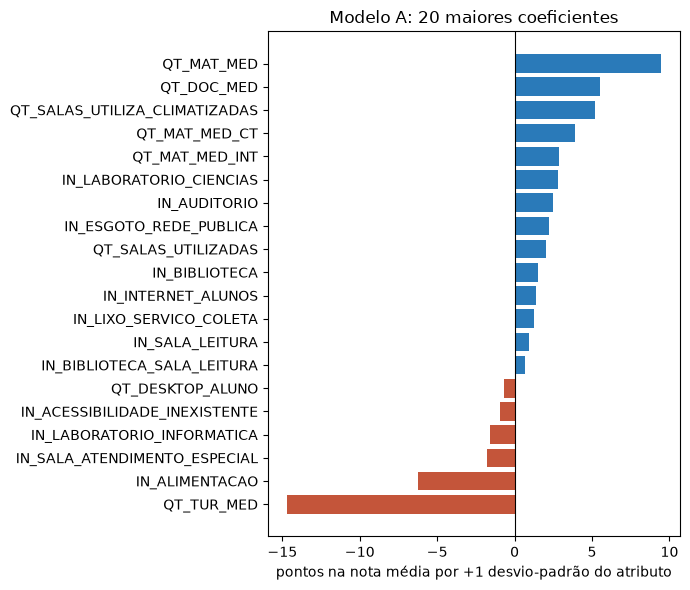

In [8]:
model_a, columns_a = models["Linear A (com rede)"]
model_a.fit(X[columns_a], y)

names = model_a.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.Series(model_a.named_steps["regressor"].coef_, index=names)
coefficients.index = coefficients.index.str.replace(r"^(num|cat)__", "", regex=True)

numeric_coefficients = coefficients[NUMERIC].sort_values(key=abs, ascending=False)
top = numeric_coefficients.head(20).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "#2a7ab9", "#c4553a"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("pontos na nota média por +1 desvio-padrão do atributo")
ax.set_title("Modelo A: 20 maiores coeficientes")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linreg_coefficients.png", dpi=150)
plt.show()

In [9]:
# Coeficientes da rede, relativos à rede estadual (a maior).
rede = coefficients.filter(like="TP_DEPENDENCIA_")
rede.index = rede.index.str.replace("TP_DEPENDENCIA_", "").map(
    {"1": "Federal", "2": "Estadual", "3": "Municipal", "4": "Privada"}
)
(rede - rede["Estadual"]).rename("diferença em relação à Estadual (pontos)").to_frame()

,diferença em relação à Estadual (pontos)
Federal,52.79
Estadual,0.00
Municipal,19.42
Privada,79.66


## 7. Resíduos (previsões fora da amostra)

`cross_val_predict` com o mesmo `cv` gera, para cada escola, a previsão do modelo treinado **sem a dobra dela**. Assim os resíduos refletem erro de generalização. Resíduo = observado − previsto, então resíduo positivo indica uma escola acima do que a estrutura prevê.

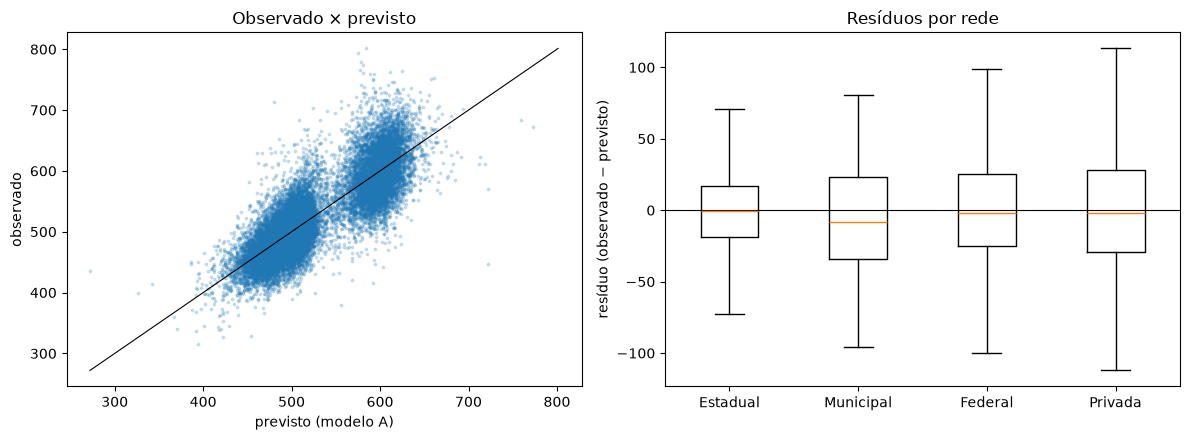

RMSE fora da amostra (todas as dobras juntas): 34.1


In [10]:
predicted = cross_val_predict(model_a, X[columns_a], y, groups=groups, cv=cv)
residuals = y - predicted

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(predicted, y, s=3, alpha=0.2)
lims = [min(y.min(), predicted.min()), max(y.max(), predicted.max())]
axes[0].plot(lims, lims, color="black", linewidth=0.8)
axes[0].set_xlabel("previsto (modelo A)")
axes[0].set_ylabel("observado")
axes[0].set_title("Observado × previsto")

rede_label = schools["TP_DEPENDENCIA"].map({1: "Federal", 2: "Estadual", 3: "Municipal", 4: "Privada"})
order = ["Estadual", "Municipal", "Federal", "Privada"]
axes[1].boxplot([residuals[rede_label == r] for r in order], tick_labels=order, showfliers=False)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("resíduo (observado − previsto)")
axes[1].set_title("Resíduos por rede")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "linreg_residuals.png", dpi=150)
plt.show()

print(f"RMSE fora da amostra (todas as dobras juntas): {np.sqrt(np.mean(residuals**2)):.1f}")

## 8. Conclusões (preencher após rodar)

- [ ] Quanto o modelo A melhora sobre o baseline da rede?
- [ ] Qual a perda ao tirar a rede (A × B)?
- [ ] Quais atributos têm os maiores coeficientes, e eles fazem sentido?
- [ ] Há padrão nos resíduos (por rede, por faixa de nota) que sugira não linearidade? Isso motiva árvores, kNN e SVR.

**Próximos passos possíveis (fora do "mais simples"):** `log1p` nas contagens (assimetria de até 18), Ridge para lidar com a colinearidade, retirada dos 6 binários quase constantes.

## Ambiente de execução

Registro das versões usadas, para conferir com `uv.lock`.

In [11]:
import platform

import sklearn

print("Python      ", platform.python_version())
for lib in (np, pd, sklearn):
    print(f"{lib.__name__:<12}", lib.__version__)
print("Plataforma  ", platform.platform())

Python       3.12.16
numpy        2.5.4
pandas       3.0.6
sklearn      1.9.1
Plataforma   Windows-11-10.0.26200-SP0
